# Experiment 2: RAG Answer Generation and Evaluation（实验二：RAG回答生成与评价）

## 1. Install Packages（安装依赖）

In [1]:
import json
import pandas as pd
from IPython.display import display
import rag_pipeline
from model_runtime import ROOT, deployment_report
from rag_pipeline import prepare, generate, judge, report, import_human_review
MODE = 'formal' 
rag_pipeline.RUN_LABEL = ''
display(deployment_report())
RUN_INFERENCE = False
print('Canonical run: rag_formal; inference enabled:', RUN_INFERENCE)

{'models': {'generator': {'repo': 'Qwen/Qwen2.5-3B-Instruct',
   'revision': 'aa8e72537993ba99e69dfaafa59ed015b17504d1',
   'path': 'D:\\CodexModels\\LegalFAQ\\hub\\models--Qwen--Qwen2.5-3B-Instruct\\snapshots\\aa8e72537993ba99e69dfaafa59ed015b17504d1'},
  'judge': {'repo': 'microsoft/Phi-3.5-mini-instruct',
   'revision': '2fe192450127e6a83f7441aef6e3ca586c338b77',
   'path': 'D:\\CodexModels\\LegalFAQ\\hub\\models--microsoft--Phi-3.5-mini-instruct\\snapshots\\2fe192450127e6a83f7441aef6e3ca586c338b77'}},
 'cache_dir': 'D:\\CodexModels\\LegalFAQ\\hub',
 'hardware': {'name': 'NVIDIA GeForce RTX 3060 Laptop GPU',
  'total_vram_mb': 6143.5},
 'versions': {'torch': '2.5.1+cu121',
  'transformers': '4.57.6',
  'bitsandbytes': '0.48.2',
  'accelerate': '1.15.0',
  'huggingface-hub': '0.36.2'},
 'quantization': 'NF4 double quantization, FP16 compute, SDPA, batch=1'}

Canonical run: rag_formal; inference enabled: False


In [2]:
corpus, sample, output_dir, manifest = prepare(MODE)
print(f'{len(sample)} queries; {len(sample) * 4} generated answers')
display(sample.head())

400 queries; 1600 generated answers


,query_id,doc_id,query_type,query,corpus_query_index
0,Q000006,1,original,Can I file an FIR online in Tamil Nadu?,5
1,Q000007,1,formal,How can one file an FIR online in Tamil Nadu?,6
2,Q000008,1,casual,"Anyways, how do I file an FIR online in TN?",7
3,Q000009,1,search,What's the process to file an online FIR in Ta...,8
4,Q000010,1,hard,Where can I submit an electronic report in Tam...,9


## 2. Answer Generation（回答生成）

In [3]:
if RUN_INFERENCE:
    answers = generate(MODE)
else:
    answers = rag_pipeline.export_answers(output_dir)
    assert len(answers) == len(sample) * 4, 'Enable RUN_INFERENCE to generate missing answers.'
display(answers[['query_id', 'system', 'answer', 'seconds', 'hit_token_limit']].head(8))

,query_id,system,answer,seconds,hit_token_limit
0,Q000006,BM25-RAG,"Yes, you can file an e-FIR for certain crimes ...",8.771047,False
1,Q000006,Dense-RAG,"Yes, you can file an e-FIR for certain crimes ...",8.474653,False
2,Q000006,No-RAG,"To file an FIR online in Tamil Nadu, you need ...",5.359758,False
3,Q000006,RRF-RAG,"Yes, you can file an e-FIR for certain crimes ...",9.217735,False
4,Q000007,BM25-RAG,"To file an FIR online in Tamil Nadu, go to the...",9.003125,False
5,Q000007,Dense-RAG,"To file an FIR online in Tamil Nadu, visit the...",8.983497,False
6,Q000007,No-RAG,"To file an FIR online in Tamil Nadu, visit the...",4.240020,False
7,Q000007,RRF-RAG,"To file an FIR online in Tamil Nadu, visit the...",8.463491,False


## 3. Automatic Evaluation Criteria（自动评价标准）

- Correctness：0 = 错误或无实质回答；1 = 部分正确但有重要遗漏；2 = 正确且覆盖参考答案的主要事实。
- Relevance：0 = 未回答问题；1 = 部分回答；2 = 直接回答问题。
- Faithfulness：0 = 主要事实与实际证据矛盾或无支持；1 = 部分事实有支持；2 = 所有实质事实均有支持。无上下文或只有无事实主张的拒答时为 N/A。

In [4]:
recovered = rag_pipeline.recover_saved_judgments(output_dir)
print('Recovered saved JSON:', recovered)
if RUN_INFERENCE:
    judge(MODE)
assert len(list((output_dir / 'judgments').glob('*.json'))) == len(sample) * 4

Recovered saved JSON: 0


## 4. Summary and Confidence Intervals（汇总与置信区间）

- 主表均值与95%置信区间使用同一完整配对 FAQ 集合；Faithfulness 不包含 No-RAG。
- 有效引用必须指向实际提供的证据编号；编号有效不代表陈述受到证据支持。

Main comparison: paired complete-FAQ means and matching 95% CIs. All-available descriptive means are saved separately.


Main comparison: paired complete-FAQ means; same samples as the CIs below.


,correctness,relevance,faithfulness,reference_token_f1_proxy
system,,,,
No-RAG,1.1275,1.2800,NaN,0.3145
BM25-RAG,1.9200,1.9350,1.9690,0.5266
Dense-RAG,1.9975,2.0000,1.9972,0.5778
RRF-RAG,1.9675,1.9725,1.9915,0.5601


,method,metric,estimate,ci_low,ci_high,n_groups
0,BM25-RAG,correctness,1.9200,1.8775,1.9550,80
1,Dense-RAG,correctness,1.9975,1.9925,2.0000,80
2,No-RAG,correctness,1.1275,1.0650,1.1950,80
3,RRF-RAG,correctness,1.9675,1.9475,1.9850,80
24,BM25-RAG,relevance,1.9350,1.8925,1.9675,80
25,Dense-RAG,relevance,2.0000,2.0000,2.0000,80
26,No-RAG,relevance,1.2800,1.2050,1.3550,80
27,RRF-RAG,relevance,1.9725,1.9525,1.9900,80
48,BM25-RAG,faithfulness,1.9690,1.9493,1.9859,71
49,Dense-RAG,faithfulness,1.9972,1.9915,2.0000,71


Coverage and citation diagnostics: all answers, not the paired analysis subset.


,system,judge_status,count
0,BM25-RAG,ok,400
1,Dense-RAG,ok,400
2,No-RAG,ok,400
3,RRF-RAG,ok,400


,system,n_answers,n_valid_correctness,n_valid_relevance,n_valid_faithfulness,invalid_citation_count,has_invalid_citation
0,BM25-RAG,400,400,400,391,0.0675,0.0650
1,Dense-RAG,400,400,400,400,0.1300,0.1275
2,No-RAG,400,400,400,0,0.7650,0.7650
3,RRF-RAG,400,400,400,396,0.1300,0.1250


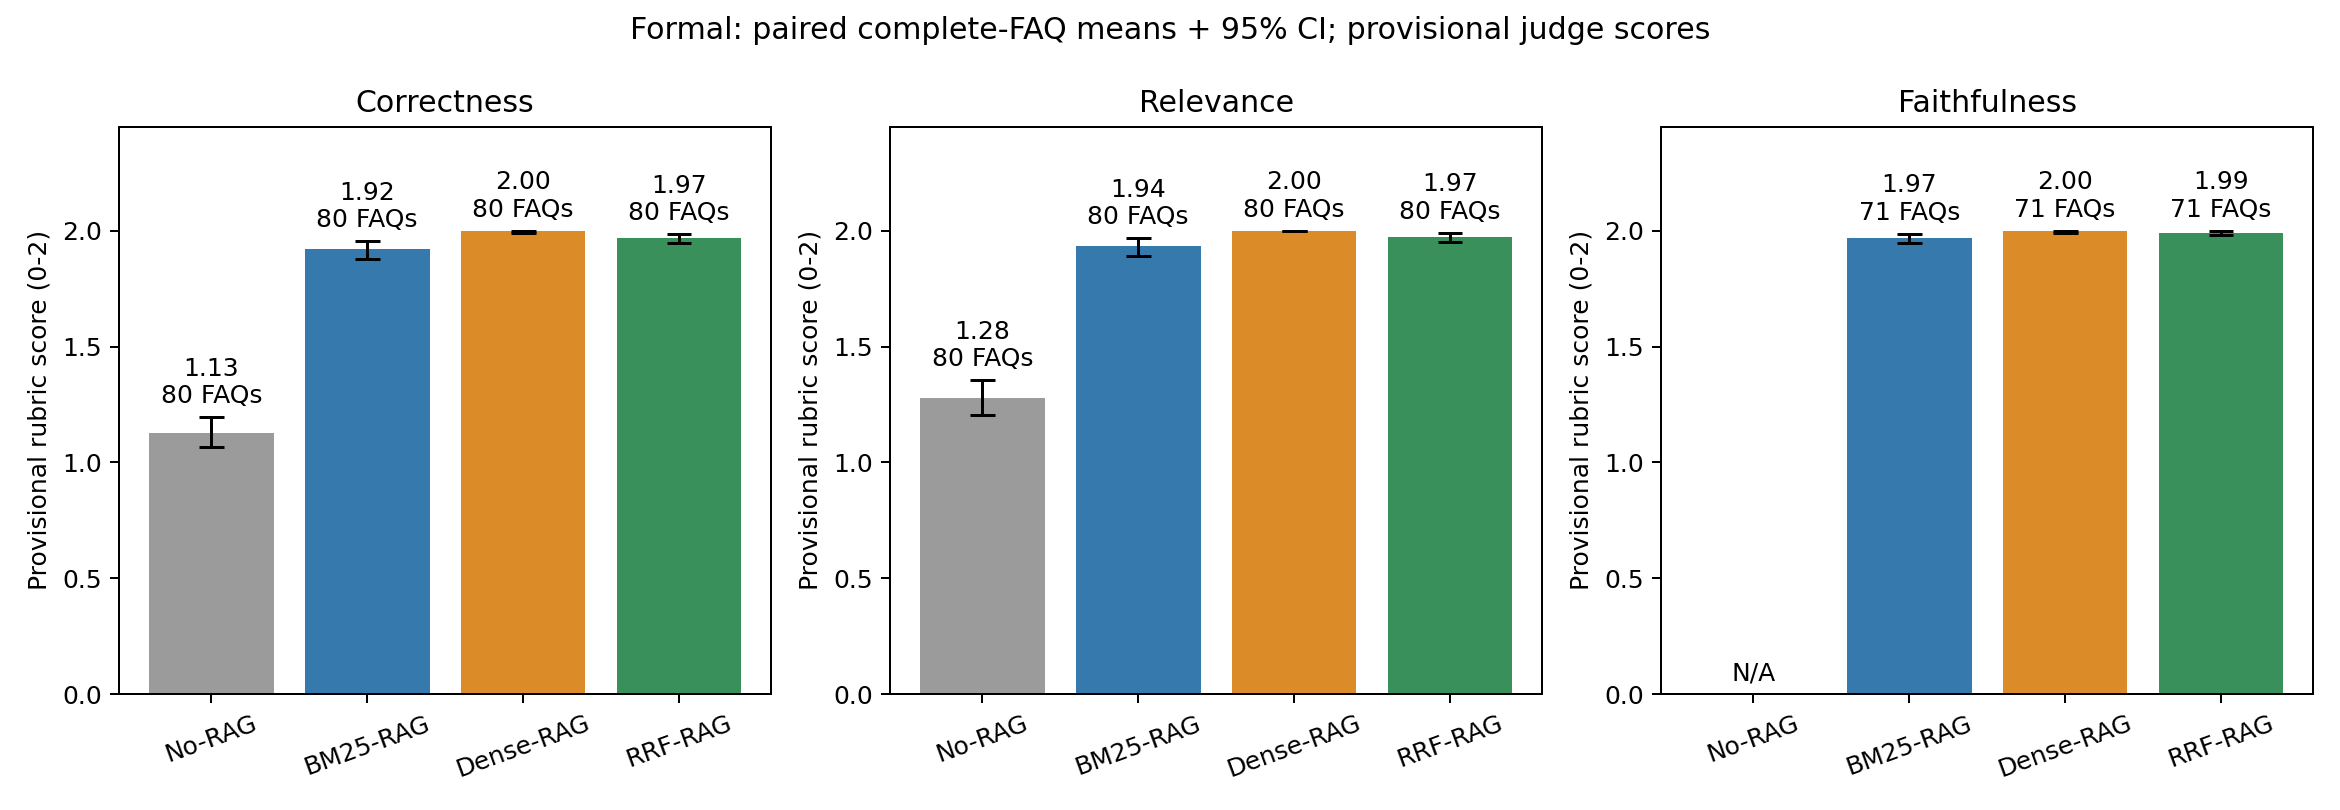

In [5]:
summary = report(MODE)
print('Main comparison: paired complete-FAQ means; same samples as the CIs below.')
display(summary[['correctness', 'relevance', 'faithfulness', 'reference_token_f1_proxy']].round(4))
intervals = pd.read_csv(output_dir / 'answer_bootstrap_ci.csv')
display(intervals.loc[intervals['query_type'] == 'overall',
                      ['method', 'metric', 'estimate', 'ci_low', 'ci_high', 'n_groups']].round(4))
print('Coverage and citation diagnostics: all answers, not the paired analysis subset.')
display(pd.read_csv(output_dir / 'judge_coverage.csv'))
available = pd.read_csv(output_dir / 'answer_quality_available_case_summary.csv')
display(available[['system', 'n_answers', 'n_valid_correctness', 'n_valid_relevance',
                   'n_valid_faithfulness', 'invalid_citation_count', 'has_invalid_citation']].round(4))
from IPython.display import Image
display(Image(filename=str(output_dir / 'answer_quality_comparison.png')))


In [6]:
evaluated = pd.read_csv(output_dir / 'answer_evaluation.csv')
display(evaluated[['query_id', 'system', 'correctness', 'relevance', 'faithfulness', 'judge_reason']].head(12))

,query_id,system,correctness,relevance,faithfulness,judge_reason
0,Q000006,BM25-RAG,2,2,2.0,Candidate answer correctly states the possibil...
1,Q000006,Dense-RAG,2,2,2.0,Candidate answer correctly states e-FIR filing...
2,Q000006,No-RAG,2,2,NaN,Candidate answer correctly states the method t...
3,Q000006,RRF-RAG,2,2,2.0,Candidate correctly states e-FIR filing online...
4,Q000007,BM25-RAG,2,2,2.0,Candidate answer correctly and directly addres...
5,Q000007,Dense-RAG,2,2,2.0,Candidate answer directly addresses the questi...
6,Q000007,No-RAG,2,2,NaN,Candidate answer correctly describes the proce...
7,Q000007,RRF-RAG,2,2,2.0,Candidate answer directly addresses the questi...
8,Q000008,BM25-RAG,2,2,2.0,Candidate answer correctly describes the proce...
9,Q000008,Dense-RAG,2,2,2.0,Candidate answer correctly and directly addres...


## 5. Human Review and Calibration（人工复核与校准）

In [7]:
calibration = import_human_review(MODE)
display(calibration)
print('n_paired_reviews = 0 means the human audit is not yet completed.')

,metric,n_paired_reviews,exact_agreement,mean_absolute_difference
0,correctness,80,0.675000,0.487500
1,relevance,80,0.750000,0.250000
2,faithfulness,59,0.847458,0.152542


n_paired_reviews = 0 means the human audit is not yet completed.
